## 1. Importing Required Libraries

In this section, we import the Python libraries required for data manipulation, visualization, preprocessing, model building, and evaluation.

- Pandas is used for data manipulation.
- NumPy is used for numerical operations.
- Matplotlib and Seaborn are used for visualization.
- Scikit-learn is used for preprocessing, machine learning models, and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

## 2. Loading the Dataset

The dataset is stored in CSV format. We use Pandas to read the CSV file into a DataFrame.

After loading the dataset, we display its dimensions and the first few records to understand its structure.

In [2]:
#Loading the Dataset
df = pd.read_csv("/Users/akhil/Downloads/flavors_of_cacao.csv")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Number of rows: 1795
Number of columns: 9


,Company \n(Maker-if known),Specific Bean Origin\nor Bar Name,REF,Review\nDate,Cocoa\nPercent,Company\nLocation,Rating,Bean\nType,Broad Bean\nOrigin
0,A. Morin,Agua Grande,1876,2016,63%,France,3.75,,Sao Tome
1,A. Morin,Kpime,1676,2015,70%,France,2.75,,Togo
2,A. Morin,Atsane,1676,2015,70%,France,3.00,,Togo
3,A. Morin,Akata,1680,2015,70%,France,3.50,,Togo
4,A. Morin,Quilla,1704,2015,70%,France,3.50,,Peru


## 3. Cleaning Column Names

The original dataset contains newline characters and extra spaces in some column names. Cleaning the column names makes them easier to work with in Python and improves code readability.

In [3]:
df.columns = [
    "Company",
    "Specific_Bean_Origin",
    "REF",
    "Review_Date",
    "Cocoa_Percent",
    "Company_Location",
    "Rating",
    "Bean_Type",
    "Broad_Bean_Origin"
]

df.head()


,Company,Specific_Bean_Origin,REF,Review_Date,Cocoa_Percent,Company_Location,Rating,Bean_Type,Broad_Bean_Origin
0,A. Morin,Agua Grande,1876,2016,63%,France,3.75,,Sao Tome
1,A. Morin,Kpime,1676,2015,70%,France,2.75,,Togo
2,A. Morin,Atsane,1676,2015,70%,France,3.00,,Togo
3,A. Morin,Akata,1680,2015,70%,France,3.50,,Togo
4,A. Morin,Quilla,1704,2015,70%,France,3.50,,Peru


## 4. Understanding the Dataset

Before preprocessing, we need to understand the structure of the dataset.

We check:
- Data types
- Number of rows and columns
- Missing values
- Basic statistical information

This helps us decide which preprocessing techniques are appropriate.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1795 entries, 0 to 1794
Data columns (total 9 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Company               1795 non-null   str    
 1   Specific_Bean_Origin  1795 non-null   str    
 2   REF                   1795 non-null   int64  
 3   Review_Date           1795 non-null   int64  
 4   Cocoa_Percent         1795 non-null   str    
 5   Company_Location      1795 non-null   str    
 6   Rating                1795 non-null   float64
 7   Bean_Type             1794 non-null   str    
 8   Broad_Bean_Origin     1794 non-null   str    
dtypes: float64(1), int64(2), str(6)
memory usage: 126.3 KB


In [5]:
df.describe()

,REF,Review_Date,Rating
count,1795.000000,1795.000000,1795.000000
mean,1035.904735,2012.325348,3.185933
std,552.886365,2.927210,0.478062
min,5.000000,2006.000000,1.000000
25%,576.000000,2010.000000,2.875000
50%,1069.000000,2013.000000,3.250000
75%,1502.000000,2015.000000,3.500000
max,1952.000000,2017.000000,5.000000


In [6]:
print("Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

Shape: (1795, 9)

Column Names:
['Company', 'Specific_Bean_Origin', 'REF', 'Review_Date', 'Cocoa_Percent', 'Company_Location', 'Rating', 'Bean_Type', 'Broad_Bean_Origin']


## 5. Checking Missing Values

Missing values can cause problems during machine learning model training.

We check the number of missing values in every column. If missing values exist, they will be handled during preprocessing using appropriate imputation techniques.

In [7]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
Company                 0
Specific_Bean_Origin    0
REF                     0
Review_Date             0
Cocoa_Percent           0
Company_Location        0
Rating                  0
Bean_Type               1
Broad_Bean_Origin       1
dtype: int64


## 6. Checking Duplicate Records

Duplicate records can cause certain observations to have more influence on the model than they should.

Therefore, we check for duplicate rows before model training.

In [8]:
duplicate_count = df.duplicated().sum()

print("Number of duplicate records:", duplicate_count)

Number of duplicate records: 0


In [9]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (1795, 9)


## 7. Converting Cocoa Percentage to Numerical Format

The `Cocoa_Percent` column is stored as text because the values contain the `%` symbol.

Machine learning algorithms require numerical input for this feature, so we remove the `%` symbol and convert the values into floating-point numbers.

In [10]:
df["Cocoa_Percent"] = (
    df["Cocoa_Percent"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

df["Cocoa_Percent"].head()

0    63.0
1    70.0
2    70.0
3    70.0
4    70.0
Name: Cocoa_Percent, dtype: float64

## 8. Exploring the Target Variable

The target variable of this project is `Rating`.

We examine its distribution to understand how chocolate ratings are distributed in the dataset.

In [11]:
print(df["Rating"].describe())


count    1795.000000
mean        3.185933
std         0.478062
min         1.000000
25%         2.875000
50%         3.250000
75%         3.500000
max         5.000000
Name: Rating, dtype: float64


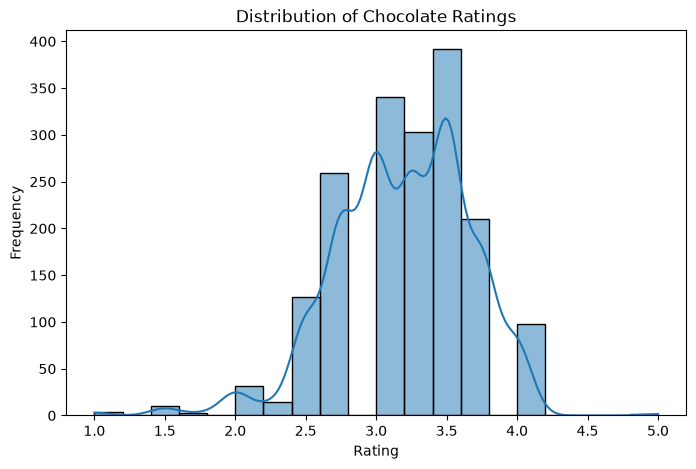

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Rating"], bins=20, kde=True)

plt.title("Distribution of Chocolate Ratings")
plt.xlabel("Rating")
plt.ylabel("Frequency")

plt.show()

## 9. Exploring Cocoa Percentage

Cocoa percentage is an important numerical feature because it represents the amount of cocoa in the chocolate.

We visualize its distribution to understand the common cocoa percentages in the dataset.

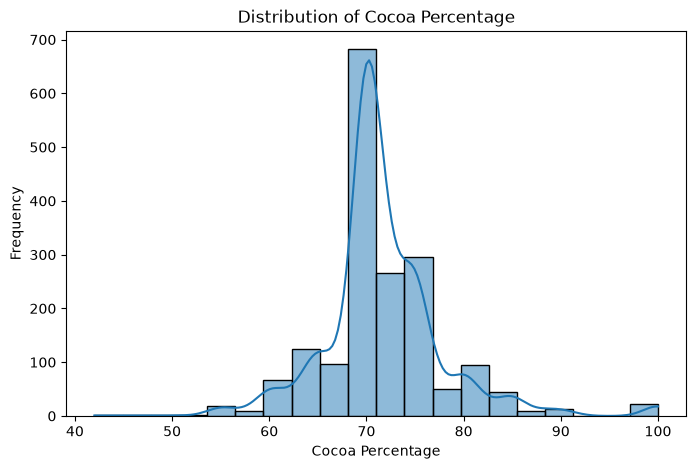

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Cocoa_Percent"], bins=20, kde=True)

plt.title("Distribution of Cocoa Percentage")
plt.xlabel("Cocoa Percentage")
plt.ylabel("Frequency")

plt.show()

## 10. Relationship Between Cocoa Percentage and Rating

We visualize the relationship between cocoa percentage and chocolate rating.

This helps us determine whether cocoa percentage appears to have a relationship with the target variable.

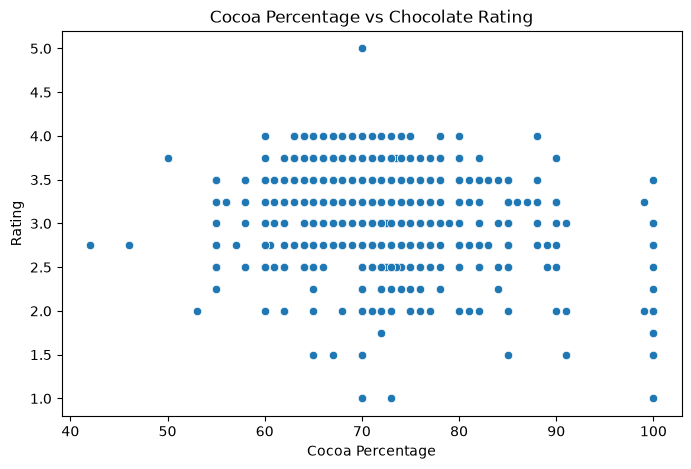

In [14]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Cocoa_Percent",
    y="Rating"
)

plt.title("Cocoa Percentage vs Chocolate Rating")
plt.xlabel("Cocoa Percentage")
plt.ylabel("Rating")

plt.show()

## 11. Chocolate Companies

The dataset contains chocolate products from many companies.

We identify the 15 companies with the highest number of reviews and visualize their average ratings.

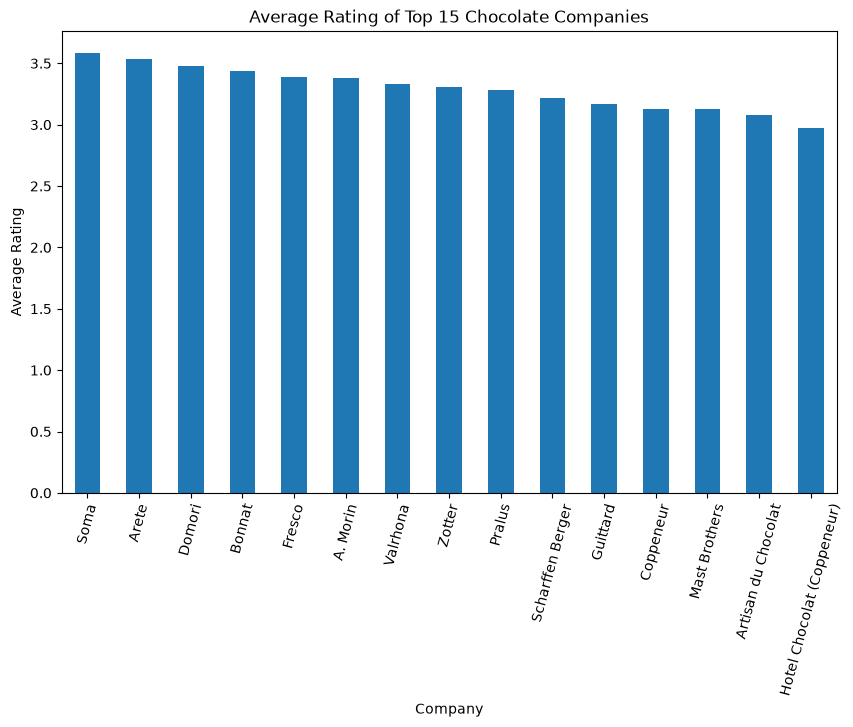

In [15]:
top_companies = df["Company"].value_counts().head(15).index

company_rating = (
    df[df["Company"].isin(top_companies)]
    .groupby("Company")["Rating"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 6))

company_rating.plot(kind="bar")

plt.title("Average Rating of Top 15 Chocolate Companies")
plt.xlabel("Company")
plt.ylabel("Average Rating")
plt.xticks(rotation=75)

plt.show()

## 12. Correlation Analysis

Correlation helps us understand the linear relationship between numerical variables.

We examine the correlation between the numerical features and the target variable.

A value close to +1 indicates a strong positive relationship, while a value close to -1 indicates a strong negative relationship.

In [16]:
numeric_df = df[
    ["REF", "Review_Date", "Cocoa_Percent", "Rating"]
]

correlation = numeric_df.corr()

print(correlation)

                    REF  Review_Date  Cocoa_Percent    Rating
REF            1.000000     0.985076       0.037791  0.101030
Review_Date    0.985076     1.000000       0.038177  0.099846
Cocoa_Percent  0.037791     0.038177       1.000000 -0.164820
Rating         0.101030     0.099846      -0.164820  1.000000


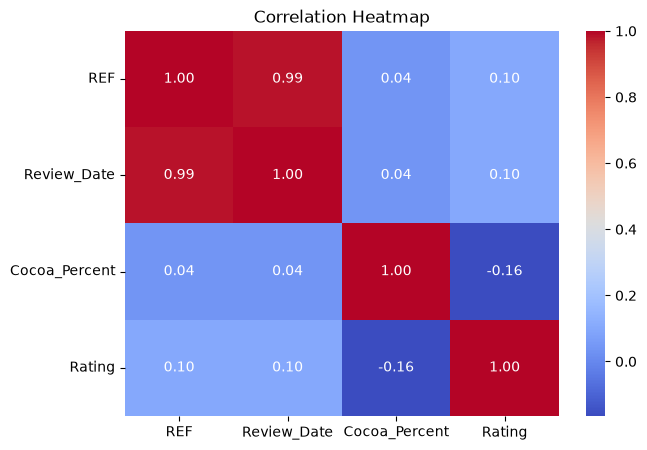

In [17]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

## 13. Outlier Detection

Outliers are observations that are unusually far from the rest of the data.

We use boxplots to investigate potential outliers in numerical variables.

We will not automatically remove every outlier because a high or low chocolate rating may represent a legitimate review.

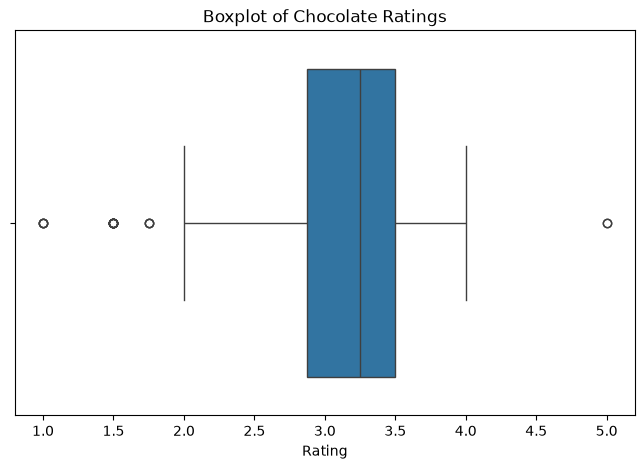

In [18]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Rating"])

plt.title("Boxplot of Chocolate Ratings")
plt.xlabel("Rating")

plt.show()

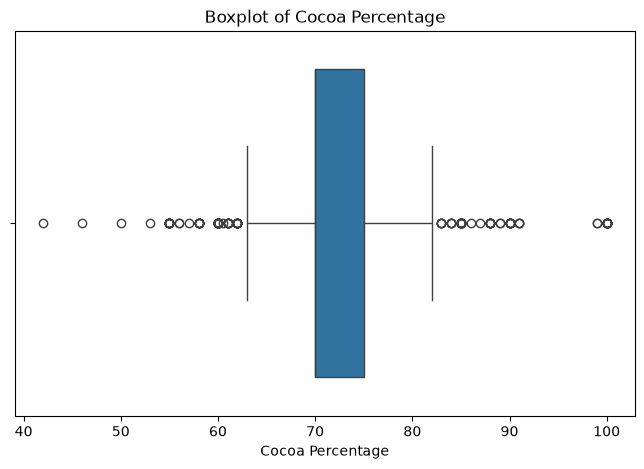

In [19]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Cocoa_Percent"])

plt.title("Boxplot of Cocoa Percentage")
plt.xlabel("Cocoa Percentage")

plt.show()

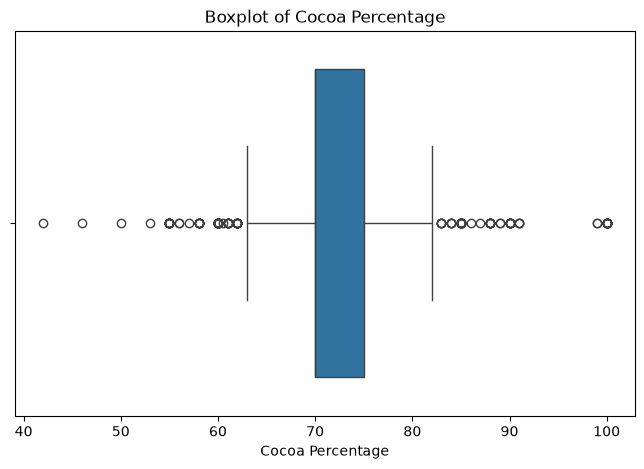

In [20]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Cocoa_Percent"])

plt.title("Boxplot of Cocoa Percentage")
plt.xlabel("Cocoa Percentage")

plt.show()

## 14. Feature Selection

The `Rating` column is selected as the target variable.

The `REF` column is excluded because it is a reference/identifier value and does not represent a meaningful characteristic of the chocolate itself.

The remaining columns are used as potential predictors.

In [21]:
X = df.drop(columns=["Rating", "REF"])
y = df["Rating"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Rating")

Features:
['Company', 'Specific_Bean_Origin', 'Review_Date', 'Cocoa_Percent', 'Company_Location', 'Bean_Type', 'Broad_Bean_Origin']

Target:
Rating


## 15. Splitting the Dataset

The dataset is divided into training and testing sets.

- 80% of the data is used for training.
- 20% is used for testing.

The model learns patterns from the training data and is evaluated on the unseen testing data.

A fixed random state is used so that the experiment can be reproduced.

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 1436
Testing samples: 359


## 16. Identifying Numerical and Categorical Features

Different types of features require different preprocessing.

Numerical features can be imputed and scaled.

Categorical features require missing-value handling and one-hot encoding so that machine learning algorithms can process them.

In [23]:
numerical_features = [
    "Review_Date",
    "Cocoa_Percent"
]

categorical_features = [
    "Company",
    "Specific_Bean_Origin",
    "Company_Location",
    "Bean_Type",
    "Broad_Bean_Origin"
]

print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)

Numerical features: ['Review_Date', 'Cocoa_Percent']
Categorical features: ['Company', 'Specific_Bean_Origin', 'Company_Location', 'Bean_Type', 'Broad_Bean_Origin']


## 17. Data Preprocessing Pipeline

We create a preprocessing pipeline.

For numerical features:
- Missing values are replaced with the median.
- Features are standardized.

For categorical features:
- Missing values are replaced with the most frequent value.
- Categories are converted into numerical values using One-Hot Encoding.

Using a pipeline ensures that the same preprocessing is applied consistently to both training and testing data.

In [24]:
numeric_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False
        ))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

## 18. Model 1 – Linear Regression

Linear Regression is used as a baseline regression model.

It assumes that the target variable can be predicted using a linear combination of the input features.

A baseline model provides a reference point for comparing more advanced models.

In [25]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(
    mean_squared_error(y_test, linear_predictions)
)
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression")
print("MAE :", linear_mae)
print("RMSE:", linear_rmse)
print("R²   :", linear_r2)

Linear Regression
MAE : 0.4296107602508029
RMSE: 0.5483561549630348
R²   : -0.30079061287989406


## 19. Model 2 – Ridge Regression

Ridge Regression is a regularized version of Linear Regression.

It adds a penalty to large model coefficients, which can help reduce overfitting, especially when there are many one-hot encoded categorical features.

In [26]:
ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge(alpha=1.0))
    ]
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

ridge_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_rmse = np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
)
ridge_r2 = r2_score(y_test, ridge_predictions)

print("Ridge Regression")
print("MAE :", ridge_mae)
print("RMSE:", ridge_rmse)
print("R²   :", ridge_r2)

Ridge Regression
MAE : 0.3449661525348702
RMSE: 0.44222118052447107
R²   : 0.15401818363860365


## 20. Model 3 – Decision Tree Regressor

A Decision Tree can learn nonlinear relationships between features and the target.

Unlike Linear Regression, it does not require the relationship between the features and target to be linear.

In [27]:
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            random_state=42,
            max_depth=10
        ))
    ]
)

tree_model.fit(X_train, y_train)

tree_predictions = tree_model.predict(X_test)

tree_mae = mean_absolute_error(y_test, tree_predictions)
tree_rmse = np.sqrt(
    mean_squared_error(y_test, tree_predictions)
)
tree_r2 = r2_score(y_test, tree_predictions)

print("Decision Tree Regressor")
print("MAE :", tree_mae)
print("RMSE:", tree_rmse)
print("R²   :", tree_r2)

Decision Tree Regressor
MAE : 0.36911367866192174
RMSE: 0.48869718818954044
R²   : -0.03314583593036047


## 21. Model 4 – Random Forest Regressor

Random Forest combines multiple decision trees and averages their predictions.

It can model nonlinear relationships and interactions between features while generally being more robust than a single decision tree.

In [28]:
forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

forest_model.fit(X_train, y_train)

forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(
    mean_squared_error(y_test, forest_predictions)
)
forest_r2 = r2_score(y_test, forest_predictions)

print("Random Forest Regressor")
print("MAE :", forest_mae)
print("RMSE:", forest_rmse)
print("R²   :", forest_r2)

Random Forest Regressor
MAE : 0.33452994428969357
RMSE: 0.4358352079819999
R²   : 0.17827486610514398


## 22. Model 5 – Gradient Boosting Regressor

Gradient Boosting builds models sequentially, with each new model attempting to improve the errors made by previous models.

It is suitable for tabular datasets and can capture complex nonlinear relationships.

In [29]:
gradient_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", GradientBoostingRegressor(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            random_state=42
        ))
    ]
)

gradient_model.fit(X_train, y_train)

gradient_predictions = gradient_model.predict(X_test)

gradient_mae = mean_absolute_error(
    y_test,
    gradient_predictions
)

gradient_rmse = np.sqrt(
    mean_squared_error(y_test, gradient_predictions)
)

gradient_r2 = r2_score(
    y_test,
    gradient_predictions
)

print("Gradient Boosting Regressor")
print("MAE :", gradient_mae)
print("RMSE:", gradient_rmse)
print("R²   :", gradient_r2)

Gradient Boosting Regressor
MAE : 0.34467787569322694
RMSE: 0.44774078455148253
R²   : 0.1327680669953074


## 23. Model Comparison

The models are compared using three evaluation metrics:

### MAE
Mean Absolute Error measures the average absolute difference between actual and predicted ratings. Lower values are better.

### RMSE
Root Mean Squared Error gives greater importance to larger prediction errors. Lower values are better.

### R² Score
R² indicates how much variation in the target is explained by the model. Higher values are better.

In [30]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting"
    ],
    
    "MAE": [
        linear_mae,
        ridge_mae,
        tree_mae,
        forest_mae,
        gradient_mae
    ],
    
    "RMSE": [
        linear_rmse,
        ridge_rmse,
        tree_rmse,
        forest_rmse,
        gradient_rmse
    ],
    
    "R2": [
        linear_r2,
        ridge_r2,
        tree_r2,
        forest_r2,
        gradient_r2
    ]
})

results.sort_values(
    by="RMSE",
    ascending=True
)

,Model,MAE,RMSE,R2
3,Random Forest,0.334530,0.435835,0.178275
1,Ridge Regression,0.344966,0.442221,0.154018
4,Gradient Boosting,0.344678,0.447741,0.132768
2,Decision Tree,0.369114,0.488697,-0.033146
0,Linear Regression,0.429611,0.548356,-0.300791


## 24. Visual Comparison of Models

A bar chart is used to compare the RMSE values of the different models.

Since RMSE measures prediction error, the model with the lowest RMSE is preferred, provided its performance is also reasonable on the other evaluation metrics.

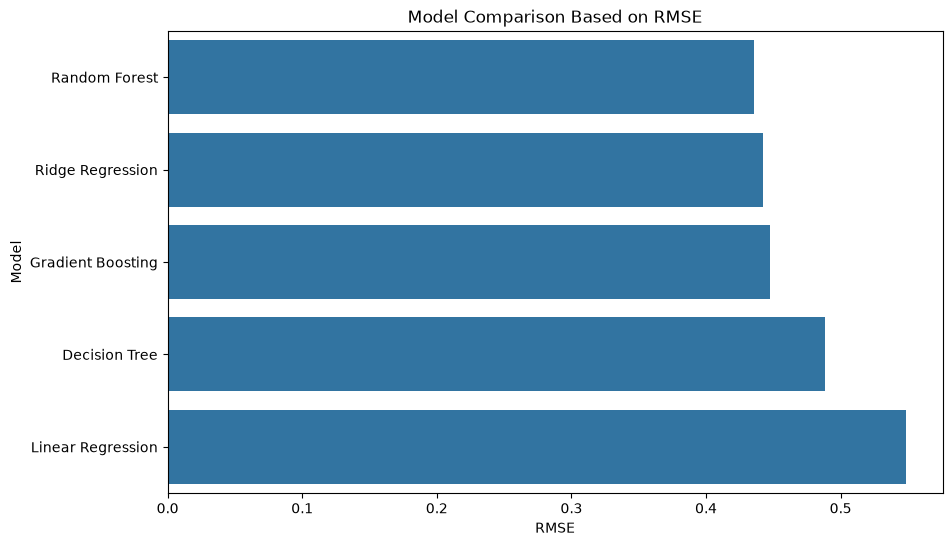

In [31]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=results.sort_values("RMSE"),
    x="RMSE",
    y="Model"
)

plt.title("Model Comparison Based on RMSE")
plt.xlabel("RMSE")
plt.ylabel("Model")

plt.show()

## 25. Hyperparameter Tuning

Hyperparameter tuning is performed to determine whether the Random Forest model can be improved.

Grid Search evaluates different combinations of hyperparameters using cross-validation.

The parameters being tested include:
- Number of trees
- Maximum tree depth
- Minimum samples required for splitting

The best combination is selected based on negative mean squared error.

In [32]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]
)

param_grid = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5]
}

grid_search = GridSearchCV(
    rf_pipeline,
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

Best Parameters:
{'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}


## 26. Evaluation of Tuned Random Forest

The best Random Forest model obtained through Grid Search is evaluated on the unseen test dataset.

This allows us to determine whether hyperparameter tuning improved the model's generalization performance.

In [33]:
best_model = grid_search.best_estimator_

tuned_predictions = best_model.predict(X_test)

tuned_mae = mean_absolute_error(
    y_test,
    tuned_predictions
)

tuned_rmse = np.sqrt(
    mean_squared_error(y_test, tuned_predictions)
)

tuned_r2 = r2_score(
    y_test,
    tuned_predictions
)

print("Tuned Random Forest")
print("MAE :", tuned_mae)
print("RMSE:", tuned_rmse)
print("R²   :", tuned_r2)

Tuned Random Forest
MAE : 0.33513428665500394
RMSE: 0.4390917753011204
R²   : 0.16594910290122522


## 27. Final Model Selection

The tuned Random Forest is compared with the previously developed models.

The final model is selected based on:
- Lower MAE
- Lower RMSE
- Higher R²
- Generalization performance on unseen test data

The model should not be selected based on a single metric alone.

In [34]:
final_results = results.copy()

final_results.loc[len(final_results)] = [
    "Tuned Random Forest",
    tuned_mae,
    tuned_rmse,
    tuned_r2
]

final_results = final_results.sort_values(
    by="RMSE",
    ascending=True
)

final_results.reset_index(drop=True)

,Model,MAE,RMSE,R2
0,Random Forest,0.334530,0.435835,0.178275
1,Tuned Random Forest,0.335134,0.439092,0.165949
2,Ridge Regression,0.344966,0.442221,0.154018
3,Gradient Boosting,0.344678,0.447741,0.132768
4,Decision Tree,0.369114,0.488697,-0.033146
5,Linear Regression,0.429611,0.548356,-0.300791


## 28. Actual vs Predicted Ratings

We compare the actual ratings with the predictions generated by the final model.

If the predictions are close to the actual ratings, the model is performing well.

In [35]:
comparison = pd.DataFrame({
    "Actual_Rating": y_test.values,
    "Predicted_Rating": tuned_predictions
})

comparison.head(20)

,Actual_Rating,Predicted_Rating
0,3.00,2.973720
1,3.75,3.409204
2,3.50,3.603056
3,3.50,3.389513
4,3.00,3.264786
5,3.00,3.209104
6,2.75,3.146661
7,3.75,3.332268
8,2.50,3.047771
9,3.25,3.802964


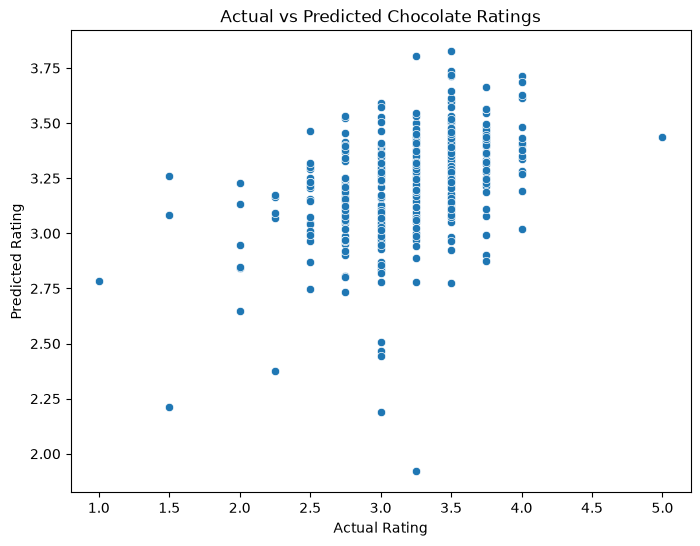

In [36]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=tuned_predictions
)

plt.xlabel("Actual Rating")
plt.ylabel("Predicted Rating")
plt.title("Actual vs Predicted Chocolate Ratings")

plt.show()

## 29. Prediction on New Unseen Data

The final trained model is now used to predict the rating of a new chocolate product.

This data was not part of the training dataset.

The same features used during model training are provided to the model.

In [37]:
new_chocolate = pd.DataFrame({
    "Company": ["A. Morin"],
    "Specific_Bean_Origin": ["Peru"],
    "Review_Date": [2026],
    "Cocoa_Percent": [70.0],
    "Company_Location": ["France"],
    "Bean_Type": ["Criollo"],
    "Broad_Bean_Origin": ["Peru"]
})

predicted_rating = best_model.predict(new_chocolate)

print("Predicted Chocolate Rating:",
      round(predicted_rating[0], 2))

Predicted Chocolate Rating: 3.3


# 30. Final Conclusion

In this project, an end-to-end machine learning pipeline was developed to predict chocolate ratings.

The dataset was first explored to understand its structure, distributions, missing values, duplicates, and relationships between variables.

The `Cocoa_Percent` feature was converted from text format into numerical format. Missing values were handled through the preprocessing pipeline, and categorical features were converted using One-Hot Encoding.

Five regression algorithms were evaluated:

1. Linear Regression
2. Ridge Regression
3. Decision Tree Regressor
4. Random Forest Regressor
5. Gradient Boosting Regressor

The models were compared using MAE, RMSE, and R² score.

Random Forest was further optimized using Grid Search and 5-fold cross-validation.

The final model was selected based on its performance on unseen test data. The selected model was then used to predict the rating of a new chocolate product.

This project demonstrates a complete machine learning workflow, from data understanding and preprocessing to model development, evaluation, tuning, and prediction.